# 01b · Extra sections for the geometry ablation

The synopsis repeats the study on two more sections, both with a steel ratio close to 0.03:

| key | section | bars (#32, 819 mm²) | layout used here |
|---|---|---|---|
| `3x3` | 914.4 x 914.4 mm | 32 | 9 bars along every face (corners shared) |
| `5x2_5` | 1524 x 762 mm | 42 | 15 along each long face, 8 along each short face (corners shared) |

The bar layouts are my assumption (only the bar counts were fixed). Change `bars_long_face` and `bars_short_face`
in `qsvm_rc/config.py` if you prefer another arrangement, then re-run this notebook.

The data are generated with the project capacity code. Section 00 already showed that this code reproduces your
main section labels, and cell 3 below repeats that check before anything is written. Grids follow your rules: Pu from
1000 kN in 250 kN steps up to the first step above $\phi P_0$, eccentricities in 10 mm steps over the first half of each half
dimension and 5 mm steps over the second half.

In [1]:
# Make the project helper package (qsvm_rc) importable from any sub-folder
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / "qsvm_rc").is_dir() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
print("Project root:", PROJECT_ROOT)

Project root: D:\LUMS PAs\3rd Semester\AI631 - Quantum Machine Learning\Project


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from qsvm_rc import config, data_utils, rc_capacity

EXTRA_SECTIONS = ["3x3", "5x2_5"]
config.EXTRA_DATA_ROOT.mkdir(parents = True, exist_ok = True)

## 1. Section constants

In [3]:
constant_rows = []
for key, section in config.SECTIONS.items():
    constants = rc_capacity.section_constants(section)
    constant_rows.append({"section": key, "title": section["title"], **constants})
constants_table = pd.DataFrame(constant_rows)
print(constants_table.round(4).to_string(index = False))
constants_table.to_csv(config.RESULTS_ROOT / "section_constants.csv", index = False)

section                    title  number_of_bars  gross_area_mm2  steel_area_mm2  steel_ratio      p0_kN  phi_p0_kN  bresler_limit_kN  beta1
    3x2       3 ft x 2 ft (main)              22       557418.24           18018       0.0323 21322.2661 13859.4730         1672.2547 0.8357
    3x3   3 ft x 3 ft (ablation)              32       836127.36           26208       0.0313 31660.3037 20579.1974         2508.3821 0.8357
  5x2_5 5 ft x 2.5 ft (ablation)              42      1161288.00           34398       0.0296 43182.8550 28068.8558         3483.8640 0.8357


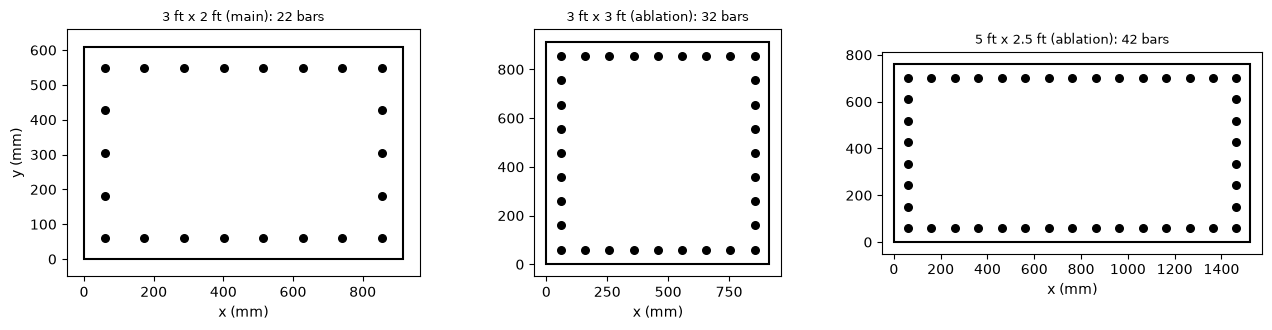

In [4]:
figure, axes = plt.subplots(1, 3, figsize = (13, 3.4))
for axis, (key, section) in zip(axes, config.SECTIONS.items()):
    bars_x, bars_y = rc_capacity.bar_coordinates(section)
    axis.add_patch(plt.Rectangle((0, 0), section["width_x_mm"], section["depth_y_mm"], fill = False, linewidth = 1.5))
    axis.scatter(bars_x, bars_y, s = 30, color = "k")
    axis.set_aspect("equal")
    axis.set_xlim(-50, section["width_x_mm"] + 50)
    axis.set_ylim(-50, section["depth_y_mm"] + 50)
    section_title = section["title"]
    axis.set_title(f"{section_title}: {len(bars_x)} bars", fontsize = 9)
    axis.set_xlabel("x (mm)")
axes[0].set_ylabel("y (mm)")
figure.tight_layout()
figure.savefig(config.figures_dir() / "section_layouts.png", dpi = 200)
plt.show()

## 2. Check against your main section data before generating anything

In [5]:
main_frame = data_utils.load_section(config.MAIN_SECTION, capacity_source = "code")
agreement = data_utils.label_agreement(main_frame)
print(f"Project code vs your main section labels: {agreement:.5f}")
print("PASS" if agreement > 0.995 else "CHECK: send me this output before using the extra sections")

regenerated = rc_capacity.generate_section_dataset(config.SECTIONS[config.MAIN_SECTION])
regenerated_rows = len(regenerated["pu_kN"])
regenerated_safe = np.mean(regenerated["status"] == "SAFE")
your_safe = np.mean(main_frame["label"] == 1)
print(f"Regenerated main grid: {regenerated_rows:,} rows (yours: {len(main_frame):,}), "
      f"SAFE {regenerated_safe:.4f} (yours: {your_safe:.4f})")

Project code vs your main section labels: 0.99999
PASS
Regenerated main grid: 168,222 rows (yours: 170,660), SAFE 0.3148 (yours: 0.3150)


## 3. Interaction diagrams (uniaxial, $\phi = 0.65$)

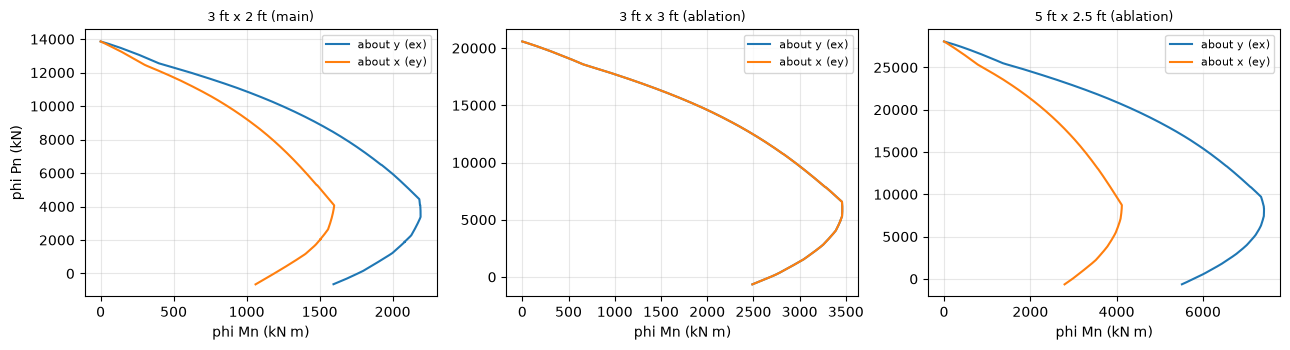

In [6]:
figure, axes = plt.subplots(1, 3, figsize = (13, 3.6))
for axis, (key, section) in zip(axes, config.SECTIONS.items()):
    bars_x, bars_y = rc_capacity.bar_coordinates(section)
    for label, depth, breadth, layers in [("about y (ex)", section["width_x_mm"], section["depth_y_mm"], bars_x),
                                          ("about x (ey)", section["depth_y_mm"], section["width_x_mm"], bars_y)]:
        axial, moment = rc_capacity.uniaxial_interaction_curve(depth, breadth, layers, np.full(len(layers), section["bar_area_mm2"]),
                                                               section["fc_mpa"], section["fy_mpa"], number_of_points = 3000)
        keep = axial > -1e6
        axis.plot(config.PHI * moment[keep] / 1e6, config.PHI * axial[keep] / 1e3, label = label)
    axis.set_title(section["title"], fontsize = 9)
    axis.set_xlabel("phi Mn (kN m)")
    axis.grid(alpha = 0.3)
    axis.legend(fontsize = 8)
axes[0].set_ylabel("phi Pn (kN)")
figure.tight_layout()
figure.savefig(config.figures_dir() / "interaction_diagrams.png", dpi = 200)
plt.show()

## 4. Generate and save the two extra datasets

In [7]:
for key in EXTRA_SECTIONS:
    section = config.SECTIONS[key]
    generated = pd.DataFrame(rc_capacity.generate_section_dataset(section))
    generated[["pu_kN", "ex_mm", "ey_mm", "status"]].to_csv(section["dataset_path"], index = False)
    generated.to_csv(section["extended_path"], index = False)
    safe_share = np.mean(generated["status"] == "SAFE")
    valid_share = np.mean(generated["bresler_valid"])
    file_name = section["dataset_path"].name
    print(f"{key:<6} rows {len(generated):>8,}  SAFE {safe_share:.4f}  Bresler valid {valid_share:.4f}  ->  {file_name}")

3x3    rows  380,880  SAFE 0.3359  Bresler valid 1.0000  ->  25280058_AI631_Project_Dataset_3x3.csv
5x2_5  rows  733,700  SAFE 0.3439  Bresler valid 1.0000  ->  25280058_AI631_Project_Dataset_5x2_5.csv


## 5. Fixed splits for the extra sections (same protocol as the main section)

In [8]:
for key in EXTRA_SECTIONS:
    frame = data_utils.load_section(key)
    splits = data_utils.make_fixed_splits(frame, key)
    path = data_utils.save_splits(splits)
    source = frame.attrs["capacity_source"]
    agreement = data_utils.label_agreement(frame)
    pool_count = splits["pool_size"]
    print(f"{key:<6} capacity source: {source}, agreement {agreement:.5f}, pool {pool_count:,}  ->  {path}")

3x3    capacity source: extended column 'phi_pni_kN', agreement 1.00000, pool 376,880  ->  D:\LUMS PAs\3rd Semester\AI631 - Quantum Machine Learning\Project\results\3x3\splits\fixed_splits.json
5x2_5  capacity source: extended column 'phi_pni_kN', agreement 1.00000, pool 729,700  ->  D:\LUMS PAs\3rd Semester\AI631 - Quantum Machine Learning\Project\results\5x2_5\splits\fixed_splits.json


Next: `02_classical/01_classical_baselines.ipynb`.